In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import pandas as pd 
import matplotlib.pyplot as plt
import config
import dataset_build as db
import schema
import gc 
import feature_engineering as fe

DEMO_YEAR = config.PROCESSING_YEARS[0]
print(f"Region: {config.PROCESSING_REGION} | years: {config.PROCESSING_YEARS} | walkthrough year: {DEMO_YEAR}")


Region: southeast_asia | years: [2020, 2021, 2022, 2023, 2024, 2025] | walkthrough year: 2020


In [2]:
landcover_df, fire_df = db.load_landcover_and_fires()
weather_df = db.load_weather(DEMO_YEAR)

print(f"Weather grid-days ({DEMO_YEAR}): {len(weather_df):,}")
print(f"Land cover cells:          {len(landcover_df):,}")
print(f"Fire cell-days (all years): {len(fire_df):,}")

Weather grid-days (2020): 9,407,664
Land cover cells:          25,704
Fire cell-days (all years): 1,665,011


In [3]:
master_panel = db.build_analysis_panel(weather_df, landcover_df, fire_df, verbose=True)
del weather_df
master_panel.head(3)

Built master panel: 9,407,664 total rows
  Fire days (fire = 1):     348,278 (3.70%)
  Non-fire days (fire = 0): 9,059,386 (96.30%)


,grid_id,date,soil_moisture,latitude,longitude,temp_max_c,temp_mean_c,rainfall_mm,wind_speed_kmh,year,...,forest_pct,grassland_pct,cropland_pct,other_pct,landcover_coverage_pct,fire,hotspot_count,frp_max,frp_sum,country
0,10.0_105.1,2020-01-01,0.220519,10.0,105.1,31.776031,27.286469,0.977355,10.142485,2020,...,3.82,3.99,48.61,43.58,100.0,0,0,0.0,0.0,VNM
1,10.0_105.1,2020-01-02,0.217468,10.0,105.1,31.545807,27.415649,0.002140,10.625712,2020,...,3.82,3.99,48.61,43.58,100.0,0,0,0.0,0.0,VNM
2,10.0_105.1,2020-01-03,0.215768,10.0,105.1,31.021637,27.089996,0.176883,8.266259,2020,...,3.82,3.99,48.61,43.58,100.0,0,0,0.0,0.0,VNM


In [4]:
class_counts = master_panel["fire"].value_counts().sort_index()
class_pcts = master_panel["fire"].value_counts(normalize=True).sort_index() * 100

balance_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_pcts.round(2)
})
balance_summary.index = ["Non-fire (0)", "Fire (1)"]
balance_summary

,Count,Percentage (%)
Non-fire (0),9059386,96.3
Fire (1),348278,3.7


In [5]:
analysis_df = fe.add_engineered_features(master_panel, verbose=True)
del master_panel
gc.collect()

analysis_df[["date", "temp_max_c", "dry_days", "wind_speed_kmh", "is_dry_season", "fire_weather_index", "fire"]].head(5)

Added engineered features:
  day_of_year, is_dry_season, dry_wind_interaction, fire_weather_index, is_extreme_heat


,date,temp_max_c,dry_days,wind_speed_kmh,is_dry_season,fire_weather_index,fire
0,2020-01-01,31.776031,1,10.142485,1,661.91,0
1,2020-01-02,31.545807,2,10.625712,1,692.68,0
2,2020-01-03,31.021637,3,8.266259,1,501.58,0
3,2020-01-04,30.405670,4,7.098211,1,394.84,0
4,2020-01-05,30.203033,5,7.497152,1,377.69,0


In [6]:
problems = db.validate_analysis_dataset(analysis_df, verbose=True)

Primary key check: PASSED (unique grid_id, date across all rows)
Schema validation: 2 issues found:
  - Column 'soil_moisture': 4 value(s) below minimum 0
  - 732 row(s) where the four land-cover percentages do not sum to 100


In [7]:
missing_years = []
for year in config.PROCESSING_YEARS:
    if not db.analysis_year_path(year).exists():
        missing_years.append(year)

if len(missing_years) > 0:
    build_report = db.build_all_years(years=missing_years, verbose=False)
    print(build_report.to_string(index=False))
else:
    print("Every year is already built:")

for year in config.PROCESSING_YEARS:
    path = db.analysis_year_path(year)
    print(f"  {path.name}  {path.stat().st_size / 1e6:,.0f} MB")

 year    rows  grid_cells  fire_rows  fire_rate_pct  schema_problems  seconds
 2020 9407664       25704     348278           3.70                2     26.6
 2021 9381960       25704     269835           2.88                2     22.0
 2022 9381960       25704     193259           2.06                1     20.6
 2023 9381960       25704     328410           3.50                2     21.3
 2024 9407664       25704     294757           3.13                1     23.3
 2025 9381960       25704     230472           2.46                1     21.1
  analysis_2020.parquet  348 MB
  analysis_2021.parquet  348 MB
  analysis_2022.parquet  348 MB
  analysis_2023.parquet  350 MB
  analysis_2024.parquet  349 MB
  analysis_2025.parquet  345 MB


In [8]:
summary_cols = ["year", "fire", "country", "land_cover_dominant"]
all_years = db.load_analysis_dataset(columns=summary_cols)

by_year = all_years.groupby("year")["fire"].agg(rows="count", fire_days="sum")
by_year["fire_rate_pct"] = (by_year["fire_days"] / by_year["rows"] * 100).round(2)
print(f"All years: {len(all_years):,} cell-days, {int(all_years['fire'].sum()):,} with fire")
by_year

All years: 56,343,168 cell-days, 1,665,011 with fire


,rows,fire_days,fire_rate_pct
year,,,
2020,9407664,348278,3.70
2021,9381960,269835,2.88
2022,9381960,193259,2.06
2023,9381960,328410,3.50
2024,9407664,294757,3.13
2025,9381960,230472,2.46


In [9]:
comparison_cols = ["temp_max_c", "rainfall_7d_mm", "dry_days", "wind_speed_kmh", "soil_moisture", "forest_pct"]
comparison = analysis_df.groupby("fire")[comparison_cols].agg(["mean", "median", "std"]).T
comparison.columns = ["Non-Fire Days (0)", "Fire Days (1)"]
comparison.round(2)

Non-Fire Days (0)  Fire Days (1)
temp_max_c     mean                25.83          32.28
               median              27.40          32.70
               std                  7.09           3.58
rainfall_7d_mm mean                51.67           6.16
               median              32.40           0.62
               std                 63.43          16.54
dry_days       mean                 5.31          26.39
               median               0.00          15.00
               std                 13.49          28.12
wind_speed_kmh mean                 5.55           5.90
               median               4.60           5.32
               std                  3.38           2.53
soil_moisture  mean                 0.38           0.25
               median               0.41           0.25
               std                  0.10           0.08
forest_pct     mean                70.28          62.33
               median              84.31          73.53
               std                 32.26          34.47

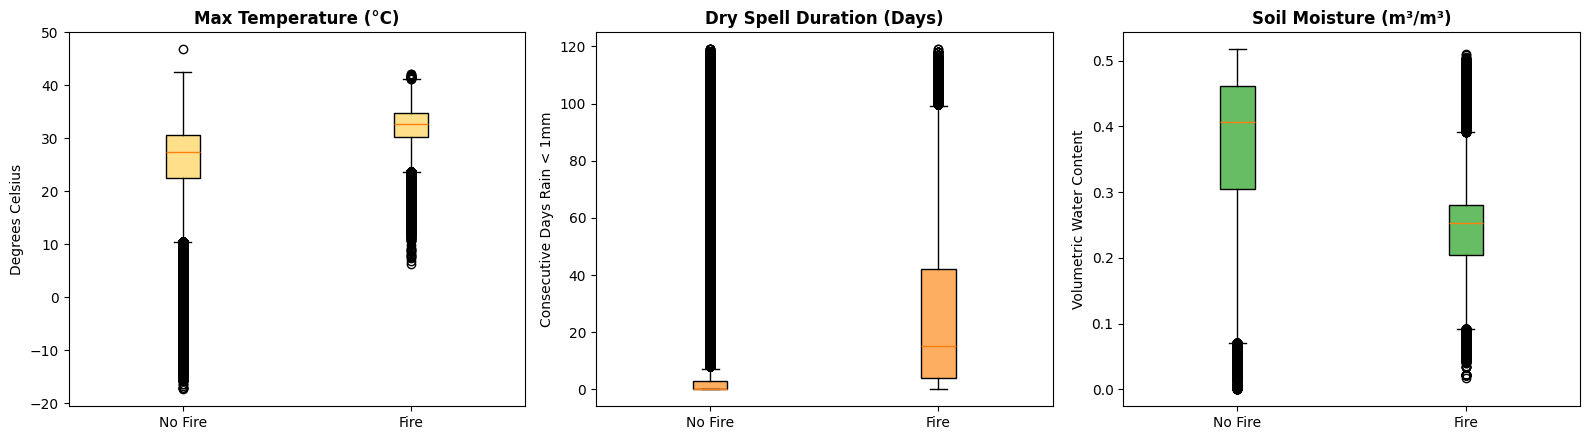

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Maximum Temperature
axes[0].boxplot([
    analysis_df.loc[analysis_df["fire"] == 0, "temp_max_c"].dropna(),
    analysis_df.loc[analysis_df["fire"] == 1, "temp_max_c"].dropna()
], tick_labels=["No Fire", "Fire"], patch_artist=True, boxprops=dict(facecolor="#fee08b"))
axes[0].set_title("Max Temperature (°C)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Degrees Celsius")

# 2. Consecutive Dry Days
axes[1].boxplot([
    analysis_df.loc[analysis_df["fire"] == 0, "dry_days"].dropna(),
    analysis_df.loc[analysis_df["fire"] == 1, "dry_days"].dropna()
], tick_labels=["No Fire", "Fire"], patch_artist=True, boxprops=dict(facecolor="#fdae61"))
axes[1].set_title("Dry Spell Duration (Days)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Consecutive Days Rain < 1mm")

# 3. Soil Moisture
axes[2].boxplot([
    analysis_df.loc[analysis_df["fire"] == 0, "soil_moisture"].dropna(),
    analysis_df.loc[analysis_df["fire"] == 1, "soil_moisture"].dropna()
], tick_labels=["No Fire", "Fire"], patch_artist=True, boxprops=dict(facecolor="#66bd63"))
axes[2].set_title("Soil Moisture (m³/m³)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Volumetric Water Content")

plt.tight_layout()
plt.show()

In [11]:
lc_fire = all_years.groupby("land_cover_dominant")["fire"].agg(total_days="count", fire_days="sum").reset_index()
lc_fire["fire_rate_pct"] = lc_fire["fire_days"] / lc_fire["total_days"] * 100

lc_fire = lc_fire.sort_values("fire_rate_pct", ascending=False).reset_index(drop=True)
lc_fire.round(2)

,land_cover_dominant,total_days,fire_days,fire_rate_pct
0,cropland,9807008,405186,4.13
1,grassland,2047328,79729,3.89
2,forest,43239392,1168050,2.70
3,other,1245056,12046,0.97


In [12]:
for year in config.PROCESSING_YEARS:
    path = db.analysis_year_path(year)
    print(f"{path}  ({path.stat().st_size / 1e6:,.0f} MB)")

D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2020.parquet  (348 MB)
D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2021.parquet  (348 MB)
D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2022.parquet  (348 MB)
D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2023.parquet  (350 MB)
D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2024.parquet  (349 MB)
D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\analysis_dataset\analysis_2025.parquet  (345 MB)
